# I. Import Libraries and Load the MNIST Dataset

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist

# Load MNIST handwritten digit dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("TensorFlow Version:", tf.__version__)
print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)
print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
TensorFlow Version: 2.21.0
Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)
Training Labels: (60000,)
Testing Labels: (10000,)


# II. Visualize MNIST Handwritten Digits

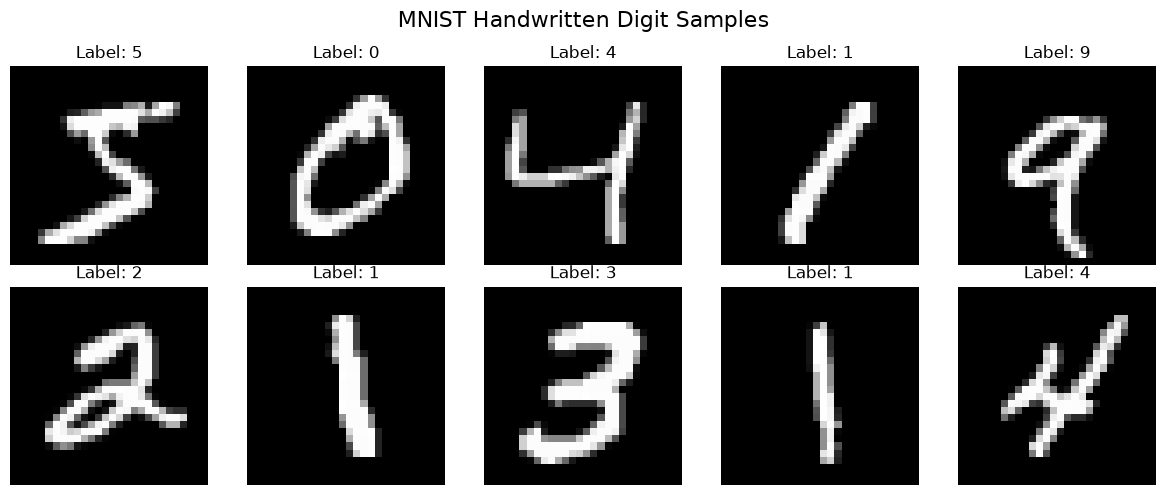

In [2]:
# Visualize 10 handwritten digits from MNIST

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("MNIST Handwritten Digit Samples", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
Why are we doing this?
This is part of Exploratory Data Analysis (EDA). It helps us understand what the images look like before training our Convolutional Neural Network.

# III. Normalize and Reshape the Images

In [3]:
# Data Preprocessing
# Normalize pixel values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Reshape images for CNN input
# Each image becomes (28, 28, 1)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Display the new shapes
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Check normalized pixel values
print("Minimum Pixel Value:", X_train.min())
print("Maximum Pixel Value:", X_train.max())

Training Data Shape: (60000, 28, 28, 1)
Testing Data Shape: (10000, 28, 28, 1)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [ ]:
What have we done?
- Normalization: Converted pixel values from 0–255 into 0–1, making training more stable.
- Reshaping: Added one channel dimension because MNIST images are grayscale.
- Prepared the dataset: Our images are now in the correct format for CNN training.

# IV. Build the CNN Model Using TensorFlow/Keras

In [4]:
# Build CNN Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

model = Sequential([
    Input(shape=(28, 28, 1)),

    # First convolutional layer
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Second convolutional layer
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Convert feature maps into a vector
    Flatten(),

    # Fully connected layer
    Dense(128, activation="relu"),
    Dropout(0.3),

    # Output layer: 10 digits (0-9)
    Dense(10, activation="softmax")
])

# Display model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
What does each layer do?
- Conv2D: Learns patterns such as edges, curves, and shapes in handwritten digits.
- MaxPooling2D: Reduces the size of feature maps.
- Flatten: Converts the extracted features into a one-dimensional vector.
- Dense: Learns how to classify the extracted features.
- Dropout: Helps reduce overfitting during training.
- Softmax: Produces a probability distribution across the 10 digit classes.

# V. Compile the CNN Model

In [5]:
#Compile CNN Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [ ]:
What does this code mean?
Component	                                         Purpose
adam	                           Optimizer that adjusts the model's weights during training
sparse_categorical_crossentropy	   Calculates classification error for digit labels 0–9
accuracy	                       Measures the percentage of correctly classified images

We use sparse_categorical_crossentropy because our MNIST labels are integers from 0 to 9, rather than one-hot encoded vectors.

# VI. Train the CNN Model

In [6]:
#Train CNN Model
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

print("CNN Model Training Completed Successfully!")

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 37s 40ms/step - accuracy: 0.9357 - loss: 0.2102 - val_accuracy: 0.9830 - val_loss: 0.0518
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 39ms/step - accuracy: 0.9794 - loss: 0.0694 - val_accuracy: 0.9885 - val_loss: 0.0424
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 34s 41ms/step - accuracy: 0.9849 - loss: 0.0492 - val_accuracy: 0.9903 - val_loss: 0.0365
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 34s 40ms/step - accuracy: 0.9884 - loss: 0.0382 - val_accuracy: 0.9915 - val_loss: 0.0290
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 39ms/step - accuracy: 0.9898 - loss: 0.0318 - val_accuracy: 0.9910 - val_loss: 0.0329
CNN Model Training Completed Successfully!


In [ ]:
What these settings mean
Parameter	                        Meaning
epochs=5	              The model trains for 5 rounds
batch_size=64	          Processes 64 images per batch
validation_split=0.1	  Uses 10% of training data for validation
verbose=1	              Displays training progress

Because of the validation split, the model will use 54,000 images for training and 6,000 for validation.
The separate 10,000 test images remain untouched for final evaluation.

# VII. Evaluate the CNN Model

In [7]:
#Evaluate CNN Model on Test Data
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nCNN Model Evaluation Results")
print("----------------------------")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9909 - loss: 0.0288

CNN Model Evaluation Results
----------------------------
Test Accuracy: 99.09%
Test Loss: 0.0288


# VIII. Generate Predictions and Create a Confusion Matrix

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


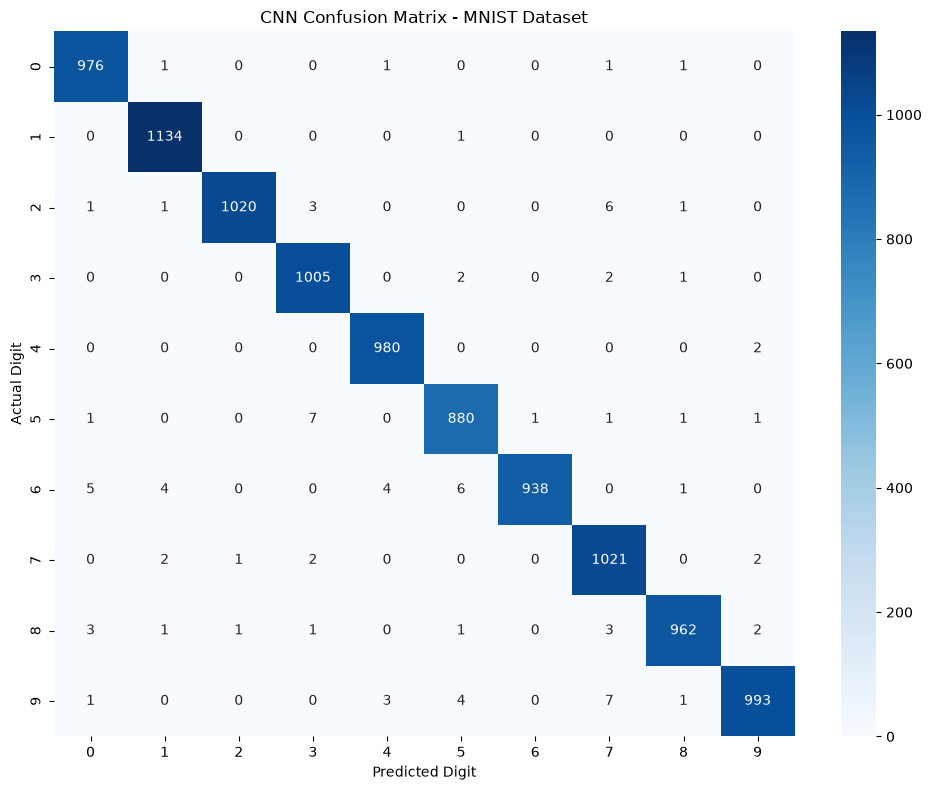

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       1.00      0.99      0.99      1032
           3       0.99      1.00      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.98      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [8]:
#Generate Predictions and Confusion Matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Generate predictions on test images
y_prob = model.predict(X_test)

# Convert probabilities to predicted digit labels
y_pred = np.argmax(y_prob, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("CNN Confusion Matrix - MNIST Dataset")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.tight_layout()
plt.show()

# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# IX. Plot Training and Validation Accuracy and Loss

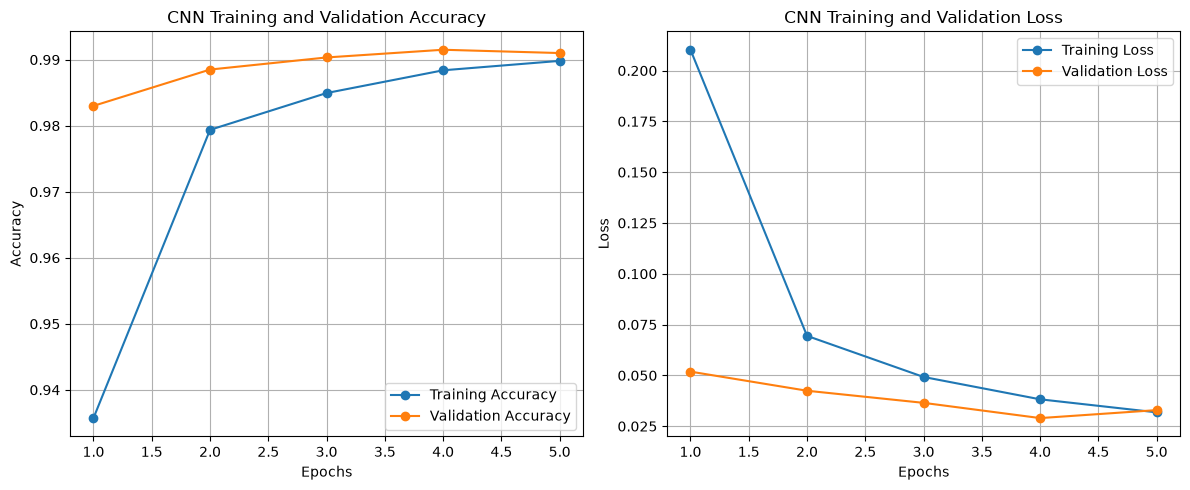

In [9]:
#Training and Validation Performance
import matplotlib.pyplot as plt

epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 5))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"],
         marker="o", label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"],
         marker="o", label="Validation Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"],
         marker="o", label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"],
         marker="o", label="Validation Loss")
plt.title("CNN Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# X. Save the Trained CNN Model

In [10]:
#Save Trained CNN Model
import os

# Create a folder to store the trained model
os.makedirs("models", exist_ok=True)

# Save the trained CNN model
model.save("models/mnist_cnn_model.keras")

print("CNN Model Saved Successfully!")
print("Model Location: models/mnist_cnn_model.keras")

CNN Model Saved Successfully!
Model Location: models/mnist_cnn_model.keras


# XI. Load the Saved Model and Predict a Handwritten Digit

Actual Digit: 7
Predicted Digit: 7
Confidence: 100.00%


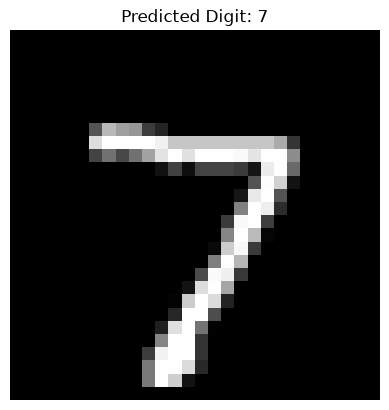

In [11]:
#Load Saved Model and Test Prediction
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load the saved CNN model
loaded_model = tf.keras.models.load_model(
    "models/mnist_cnn_model.keras"
)

# Select an image from the test dataset
image = X_test[0]

# Prepare image for prediction
image_input = np.expand_dims(image, axis=0)

# Predict the handwritten digit
prediction = loaded_model.predict(image_input, verbose=0)

predicted_digit = np.argmax(prediction)
confidence = np.max(prediction) * 100

# Display results
print("Actual Digit:", y_test[0])
print("Predicted Digit:", predicted_digit)
print(f"Confidence: {confidence:.2f}%")

# Display handwritten digit
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis("off")
plt.show()

In [ ]:
What are we testing?
We're verifying that:
- The saved .keras model loads successfully.
- The model can classify an unseen MNIST image.
- The predicted digit and confidence score can be displayed.
This is important because our upcoming Streamlit application will load the same saved model.

# XII. Create the Streamlit Application File